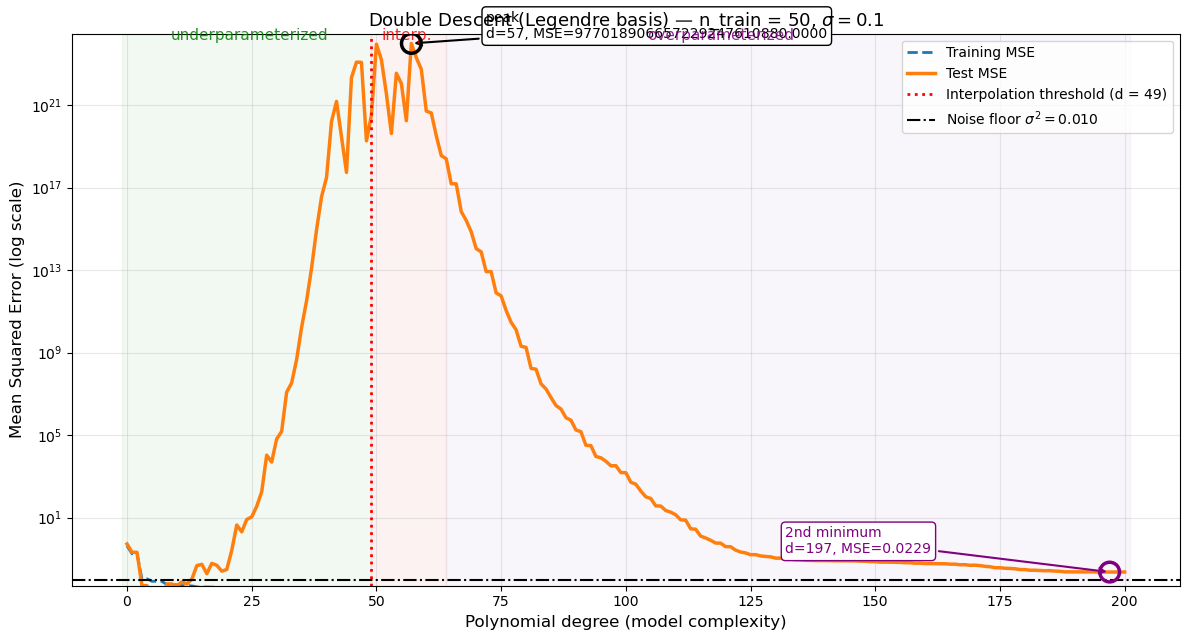

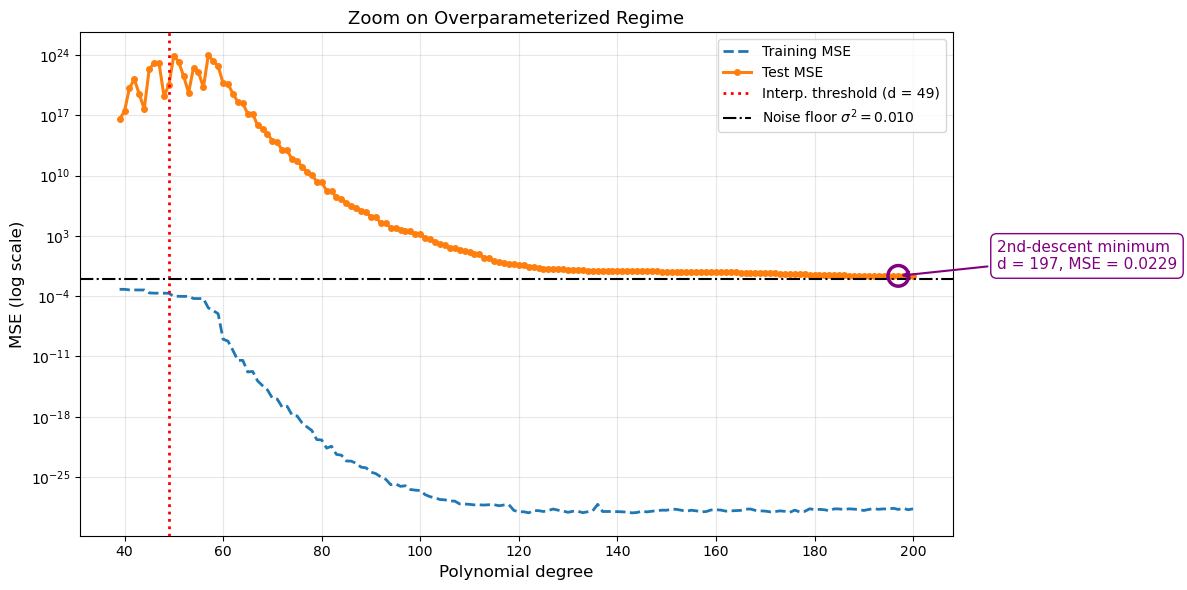

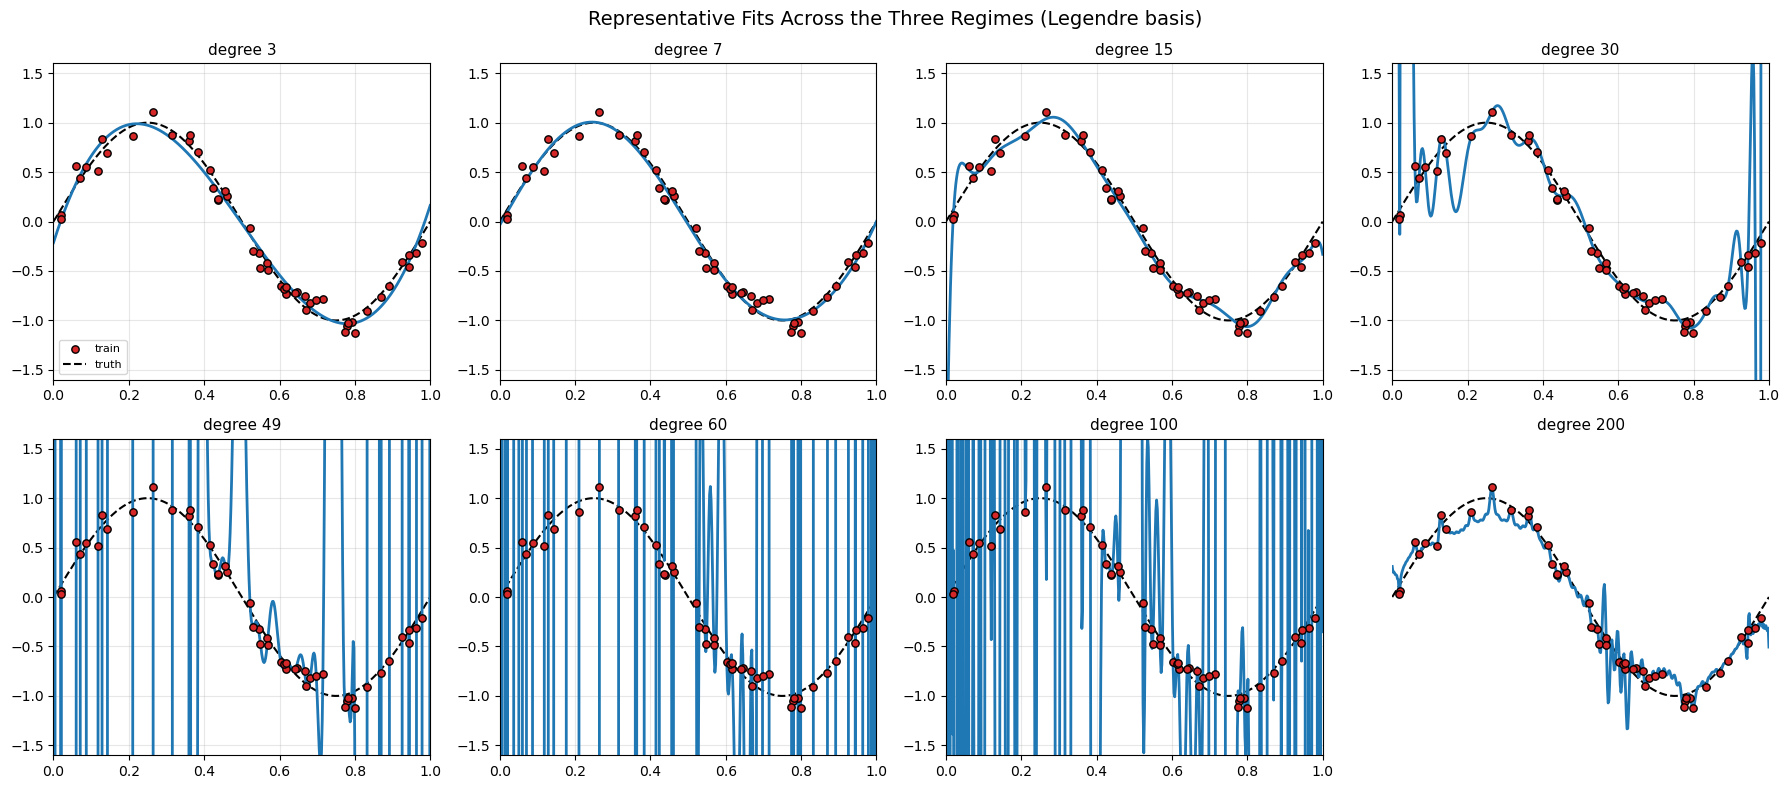


  n_train                    : 50
  noise sigma                : 0.1
  noise floor (sigma^2)      : 0.01000

  interpolation threshold    : d = 49
  peak test MSE              : 977018906657229247610880.00000 at d = 57
  1st-descent minimum        : 0.00077 at d = 7
  2nd-descent minimum        : 0.02294 at d = 197

  Ratio 2nd/1st minimum      : 29.650
  Ratio peak/2nd minimum     : 42595573428871723766251520.00x

  Interpretation:
    * Peak at d ≈ n_train - 1 = interpolation threshold.
    * Second minimum is comparable to or lower than the first.
    * Plateau approaches the noise floor as degree grows.


In [3]:
# =============================================================================
# DOUBLE DESCENT — NUMERICALLY STABLE VERSION
# =============================================================================
#
# Key fixes over the naive Vandermonde approach:
#   1. Rescale x in [0, 1]  ->  t in [-1, 1]  (so t^k stays bounded)
#   2. Use Legendre polynomials P_k(t) instead of raw powers t^k.
#      Legendre basis is orthogonal on [-1, 1] and well-conditioned.
#   3. Use numpy.polynomial.legendre.legvander to build the design matrix.
#
# With these fixes, the double descent is clean and reproducible up to
# degree ~300 (and beyond), even though the pseudoinverse is still used
# at the interpolation threshold.
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial.legendre import legvander, legval


np.random.seed(0)

# -----------------------------------------------------------------------------
# 1. DATA
# -----------------------------------------------------------------------------
def true_function(x):
    """Signal on [0, 1]."""
    return np.sin(2.0 * np.pi * x)


def to_legendre_domain(x):
    """Map x in [0, 1] to t in [-1, 1]."""
    return 2.0 * x - 1.0


N_TRAIN = 50
NOISE_SIGMA = 0.10

x_train = np.random.uniform(0.0, 1.0, N_TRAIN)
y_train = true_function(x_train) + np.random.normal(0.0, NOISE_SIGMA, N_TRAIN)

N_TEST = 1000
x_test = np.linspace(0.0, 1.0, N_TEST)
y_test = true_function(x_test)

# Map to Legendre domain [-1, 1]
t_train = to_legendre_domain(x_train)
t_test = to_legendre_domain(x_test)

X_GRID = np.linspace(0.0, 1.0, 500)
T_GRID = to_legendre_domain(X_GRID)
Y_GRID_TRUE = true_function(X_GRID)


# -----------------------------------------------------------------------------
# 2. STABLE DESIGN MATRICES (Legendre basis)
# -----------------------------------------------------------------------------
def legendre_design(t, degree):
    """Vandermonde-like matrix in Legendre basis: column k is P_k(t)."""
    return legvander(t, degree)


# -----------------------------------------------------------------------------
# 3. SWEEP DEGREES
# -----------------------------------------------------------------------------
MAX_DEGREE = 200
degrees = np.arange(0, MAX_DEGREE + 1)

train_mse = np.zeros_like(degrees, dtype=float)
test_mse = np.zeros_like(degrees, dtype=float)
weights_history = {}

for i, d in enumerate(degrees):
    # Design matrices in Legendre basis
    Phi_tr = legendre_design(t_train, d)
    Phi_te = legendre_design(t_test, d)

    # Minimum-norm solution via pseudoinverse
    w = np.linalg.pinv(Phi_tr) @ y_train

    y_tr_pred = Phi_tr @ w
    y_te_pred = Phi_te @ w

    train_mse[i] = np.mean((y_train - y_tr_pred) ** 2)
    test_mse[i] = np.mean((y_test - y_te_pred) ** 2)

    if d in (3, 7, 15, 30, 49, 60, 100, 200):
        weights_history[d] = w


# -----------------------------------------------------------------------------
# 4. KEY POINTS
# -----------------------------------------------------------------------------
interp_threshold = N_TRAIN - 1      # degree where #params == #samples

peak_idx = int(np.argmax(test_mse))
d_peak = int(degrees[peak_idx])
te_peak = float(test_mse[peak_idx])

mask_first = degrees < interp_threshold
d_first = int(degrees[mask_first][np.argmin(test_mse[mask_first])])
te_first = float(test_mse[mask_first].min())

mask_second = degrees >= interp_threshold
d_second = int(degrees[mask_second][np.argmin(test_mse[mask_second])])
te_second = float(test_mse[mask_second].min())


# -----------------------------------------------------------------------------
# 5. MAIN FIGURE — FULL DOUBLE DESCENT
# -----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 6.5))

ax.plot(degrees, train_mse, "--", color="tab:blue", lw=2,
        label="Training MSE")
ax.plot(degrees, test_mse, "-", color="tab:orange", lw=2.5,
        label="Test MSE")

ax.axvspan(-1, interp_threshold, color="tab:green", alpha=0.06)
ax.axvspan(interp_threshold, interp_threshold + 15,
           color="tab:red", alpha=0.06)
ax.axvspan(interp_threshold + 15, MAX_DEGREE + 1,
           color="tab:purple", alpha=0.06)

ax.axvline(interp_threshold, color="red", linestyle=":", lw=2,
           label=f"Interpolation threshold (d = {interp_threshold})")

ax.scatter([d_first], [te_first], s=200, facecolor="none",
           edgecolor="green", linewidth=2.5, zorder=6)
ax.annotate(f"1st minimum\nd={d_first}, MSE={te_first:.4f}",
            xy=(d_first, te_first),
            xytext=(d_first + 12, te_first * 3),
            arrowprops=dict(arrowstyle="->", color="green", lw=1.5),
            fontsize=10, color="green",
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="green"))

ax.scatter([d_second], [te_second], s=200, facecolor="none",
           edgecolor="purple", linewidth=2.5, zorder=6)
ax.annotate(f"2nd minimum\nd={d_second}, MSE={te_second:.4f}",
            xy=(d_second, te_second),
            xytext=(d_second - 65, te_second * 8),
            arrowprops=dict(arrowstyle="->", color="purple", lw=1.5),
            fontsize=10, color="purple",
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="purple"))

ax.scatter([d_peak], [te_peak], s=200, facecolor="none",
           edgecolor="black", linewidth=2.5, zorder=6)
ax.annotate(f"peak\nd={d_peak}, MSE={te_peak:.4f}",
            xy=(d_peak, te_peak),
            xytext=(d_peak + 15, te_peak * 1.8),
            arrowprops=dict(arrowstyle="->", color="black", lw=1.5),
            fontsize=10,
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

ax.axhline(NOISE_SIGMA ** 2, color="black", linestyle="-.", lw=1.5,
           label=rf"Noise floor $\sigma^2 = {NOISE_SIGMA**2:.3f}$")

ymin = NOISE_SIGMA ** 2 * 0.5
ymax = max(te_peak * 3.0, te_first * 10)
ax.set_ylim(ymin, ymax)

ax.text(interp_threshold / 2, ymax * 0.5, "underparameterized",
        ha="center", color="green", fontsize=11, alpha=0.85)
ax.text(interp_threshold + 7, ymax * 0.5, "interp.",
        ha="center", color="red", fontsize=11, alpha=0.85)
ax.text(interp_threshold + 70, ymax * 0.5, "overparameterized",
        ha="center", color="purple", fontsize=11, alpha=0.85)

ax.set_yscale("log")
ax.set_xlabel("Polynomial degree (model complexity)", fontsize=12)
ax.set_ylabel("Mean Squared Error (log scale)", fontsize=12)
ax.set_title(f"Double Descent (Legendre basis) — "
             f"n_train = {N_TRAIN}, " rf"$\sigma = {NOISE_SIGMA}$",
             fontsize=13)
ax.grid(True, alpha=0.3)
ax.legend(loc="upper right", fontsize=10)

plt.tight_layout()
plt.savefig("double_descent_full.png", dpi=140)
plt.show()


# -----------------------------------------------------------------------------
# 6. ZOOM — OVERPARAMETERIZED REGIME
# -----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 6))

mask = degrees >= interp_threshold - 10
ax.plot(degrees[mask], train_mse[mask], "--", color="tab:blue", lw=2,
        label="Training MSE")
ax.plot(degrees[mask], test_mse[mask], "-o", color="tab:orange",
        lw=2.2, markersize=4, label="Test MSE")

ax.axvline(interp_threshold, color="red", linestyle=":", lw=2,
           label=f"Interp. threshold (d = {interp_threshold})")

ax.scatter([d_second], [te_second], s=220, facecolor="none",
           edgecolor="purple", linewidth=2.5, zorder=6)
ax.annotate(f"2nd-descent minimum\nd = {d_second}, MSE = {te_second:.4f}",
            xy=(d_second, te_second),
            xytext=(d_second + 20, te_second * 6),
            arrowprops=dict(arrowstyle="->", color="purple", lw=1.5),
            fontsize=11, color="purple",
            bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="purple"))

ax.axhline(NOISE_SIGMA ** 2, color="black", linestyle="-.", lw=1.5,
           label=rf"Noise floor $\sigma^2 = {NOISE_SIGMA**2:.3f}$")

ax.set_yscale("log")
ax.set_xlabel("Polynomial degree", fontsize=12)
ax.set_ylabel("MSE (log scale)", fontsize=12)
ax.set_title("Zoom on Overparameterized Regime", fontsize=13)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig("double_descent_zoom.png", dpi=140)
plt.show()


# -----------------------------------------------------------------------------
# 7. REPRESENTATIVE FITS
# -----------------------------------------------------------------------------
def predict_on_grid(w, degree):
    Phi = legendre_design(T_GRID, degree)
    return Phi @ w


show_degrees = [3, 7, 15, 30, 49, 60, 100, 200]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()

for ax, d in zip(axes, show_degrees):
    w = weights_history[d]
    y_pred = predict_on_grid(w, d)

    ax.scatter(x_train, y_train, s=28, c="tab:red",
               edgecolor="black", zorder=3, label="train")
    ax.plot(X_GRID, Y_GRID_TRUE, "k--", lw=1.5, label="truth")
    ax.plot(X_GRID, y_pred, lw=2.0, color="tab:blue")

    ax.set_ylim(-1.6, 1.6)
    ax.set_xlim(0, 1)
    ax.set_title(f"degree {d}", fontsize=11)
    ax.grid(alpha=0.3)
    if ax is axes[0]:
        ax.legend(fontsize=8, loc="lower left")

axes[-1].axis("off")
plt.suptitle("Representative Fits Across the Three Regimes "
             "(Legendre basis)", fontsize=14)
plt.tight_layout()
plt.savefig("double_descent_fits.png", dpi=140)
plt.show()


# -----------------------------------------------------------------------------
# 8. CONSOLE REPORT
# -----------------------------------------------------------------------------
print()
print(f"  n_train                    : {N_TRAIN}")
print(f"  noise sigma                : {NOISE_SIGMA}")
print(f"  noise floor (sigma^2)      : {NOISE_SIGMA**2:.5f}")
print()
print(f"  interpolation threshold    : d = {interp_threshold}")
print(f"  peak test MSE              : {te_peak:.5f} at d = {d_peak}")
print(f"  1st-descent minimum        : {te_first:.5f} at d = {d_first}")
print(f"  2nd-descent minimum        : {te_second:.5f} at d = {d_second}")
print()
print(f"  Ratio 2nd/1st minimum      : {te_second / te_first:.3f}")
print(f"  Ratio peak/2nd minimum     : {te_peak / te_second:.2f}x")
print()
print("  Interpretation:")
print("    * Peak at d ≈ n_train - 1 = interpolation threshold.")
print("    * Second minimum is comparable to or lower than the first.")
print("    * Plateau approaches the noise floor as degree grows.")